# Lensed CMB skies → contrastive views (current PoC pipeline)

A walkthrough of how the skies and training pairs for the contrastive CMB-anomaly
proof of concept are made. It is temperature only, at nside 64, and every step calls
the library in `skysimulation/lensed_sky.py`, so what you see here is exactly what the
generation and training scripts do.

**Concept.** A contrastive encoder is trained on **ΛCDM skies only**. It learns what
distinguishes one universe from another and is invariant to orientation and to the
instrument. A sky is anomalous if it lands in a low-density region of the ΛCDM
embedding cloud. The final number is one global statistic, calibrated on held-out
ΛCDM sims. The target is robustness to the look-elsewhere effect; the real sky is
only scored once the pipeline is frozen.

**Order of operations.** Every ingredient is placed in the frame it lives in:

| # | Step | Frame | Where |
|---|---|---|---|
| 1 | Draw unlensed T and φ jointly (keeps the ISW–lensing correlation) | sky | Stage 1 |
| 2 | Anomaly (test sets) or modulation (hard negatives) on the **primordial, unlensed** T | sky | Stage 1 |
| 3 | Lens (lenspyx) | sky | Stage 1 |
| 4 | *Training only:* rescale to the fiducial $C_\ell$ (a training device, not physics) | sky | on the fly |
| 5 | Random rotation of the sky | — | Stage 2, per view |
| 6 | Beam (160′) | instrument, isotropic | Stage 2 |
| 7 | Anisotropic noise, fixed in Galactic/ecliptic coordinates | instrument | Stage 2 |
| 8 | Galactic mask, **last** | Galactic | Stage 2 |

Code map:

* **Physics:** `SkySimulation/src/skysimulation/lensed_sky.py`
* **Sim sets:** `SkySimulation/examples/contrastive_poc/generate_contrastive_poc_skies.py` and
  `calibrate_modulation_eps.py` (same folder; see its README)
* **Pairs, model, loss:** `cmb-latent/contrastive_common.py`
* **Training and scoring:** `cmb-latent/contrastive_train.py` and `contrastive_eval.py`

The previous version of this notebook (T/Q/U at nside 256, anomalies after lensing) is
kept as `lensed_sky_contrastive_views_v1_tqu256.ipynb`.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "8")

import json
import time
import warnings
from pathlib import Path

import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation

from skysimulation import lensed_sky as ls

warnings.filterwarnings("ignore", message=".*verbose.*")

## Configuration

These are the same settings as the PoC sim sets. Maps are at nside 64
($\ell_{\max}=191$). Unlensed fields are drawn to $\ell=1200$ and lensed on an nside-512
grid, because lensing moves power between scales and needs that buffer. The seeds are
the first 8 **training** skies, so we can check that this notebook reproduces the
stored skies exactly.

In [2]:
CFG      = ls.SkyConfig(nside=64)             # lmax_unl=1200, nside_lens=512
NSIDE    = CFG.nside
LMAX     = CFG.lmax
NTHREADS = int(os.environ["OMP_NUM_THREADS"])

POC_DIR   = Path("/nvme/h/lchristodoulou/data_p318/simulations/contrastive_poc_nside64")
MASK_PATH = "/nvme/h/lchristodoulou/cmb/SkySimulation/data/Planck/COM_Mask_CMB-common-Mask-Int_2048_R3.00.fits"
SEEDS     = 910_000_000 + np.arange(8)       # = the first 8 PoC training skies

print(CFG, "| lmax =", LMAX)
print("fiducial cosmology (Planck 2018 best fit):", ls.FIDUCIAL)

SkyConfig(nside=64, lmax_unl=1200, nside_lens=512) | lmax = 191
fiducial cosmology (Planck 2018 best fit): {'H0': 67.32, 'ombh2': 0.02237, 'omch2': 0.12, 'ns': 0.9649, 'As': np.float64(2.0989031673191437e-09), 'tau': 0.0544, 'mnu': 0.06, 'omk': 0.0}


# Stage 1 — the sky (once per universe)

## 1a. Spectra

CAMB gives the unlensed TT, the lensing-potential spectra $C_L^{\phi\phi}$ and
$C_L^{\phi T}$, and the lensed TT (used only for validation). ISW is already in the
unlensed TT: CAMB includes early and late ISW by default. $C_L^{\phi T}$ is the
late-ISW × lensing correlation, which the joint draw below preserves. Non-linear
(halofit) structure enters $C_L^{\phi\phi}$ through `NonLinear_lens`.

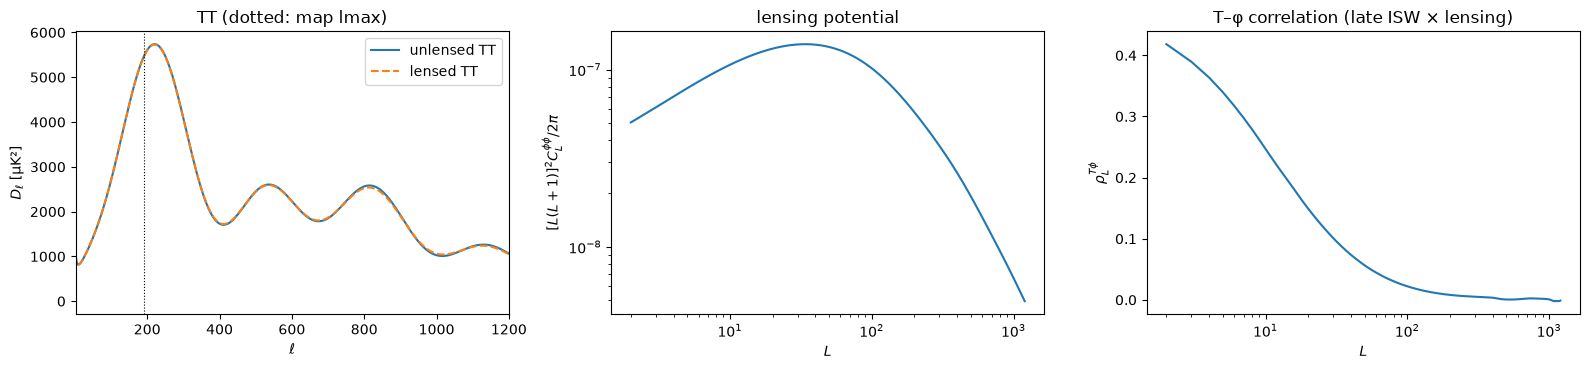

In [3]:
spec = ls.get_spectra_T(CFG)
L = np.arange(CFG.lmax_unl + 1)
dl = L * (L + 1) / (2 * np.pi)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].plot(L, dl * spec["TT"], label="unlensed TT")
ax[0].plot(L, dl * spec["len_TT"], "--", label="lensed TT")
ax[0].axvline(LMAX, color="k", lw=0.8, ls=":")
ax[0].set(xlabel=r"$\ell$", ylabel=r"$D_\ell$ [µK²]", xlim=(2, CFG.lmax_unl), title="TT (dotted: map lmax)")
ax[0].legend()
ax[1].loglog(L[2:], (L * (L + 1))[2:] ** 2 * spec["PP"][2:] / (2 * np.pi))
ax[1].set(xlabel="$L$", ylabel=r"$[L(L+1)]^2C_L^{\phi\phi}/2\pi$", title="lensing potential")
ax[2].semilogx(L[2:], spec["PT"][2:] / np.sqrt(spec["TT"][2:] * spec["PP"][2:]))
ax[2].set(xlabel="$L$", ylabel=r"$\rho_L^{T\phi}$", title="T–φ correlation (late ISW × lensing)")
plt.tight_layout()

## 1b–c. Draw (T, φ), then lens

`unlensed_T_phi` draws T and φ jointly and deterministically from a seed, so any
stored sky can be redrawn exactly. `lens_T` remaps T by the deflection
$\nabla\phi$. It is **linear in T** for fixed φ, which is used for the hard negatives
below.

In [4]:
t0 = time.time()
skies = []
for s in SEEDS:
    tlm, plm = ls.unlensed_T_phi(CFG, spec, s)
    skies.append({"seed": int(s), "tlm": tlm, "plm": plm, "alm": ls.lens_T(CFG, tlm, plm, NTHREADS)})
print(f"{len(skies)} lensed skies in {time.time() - t0:.1f} s")

if (POC_DIR / "lcdm_train.npz").exists():
    stored = np.load(POC_DIR / "lcdm_train.npz")["alm"][: len(skies)]
    rel = max(np.abs(sk["alm"] - st).max() / np.abs(sk["alm"]).max() for sk, st in zip(skies, stored))
    print(f"matches the stored PoC training skies to {rel:.1e} (float32 storage)")

8 lensed skies in 4.6 s


matches the stored PoC training skies to 4.8e-08 (float32 storage)


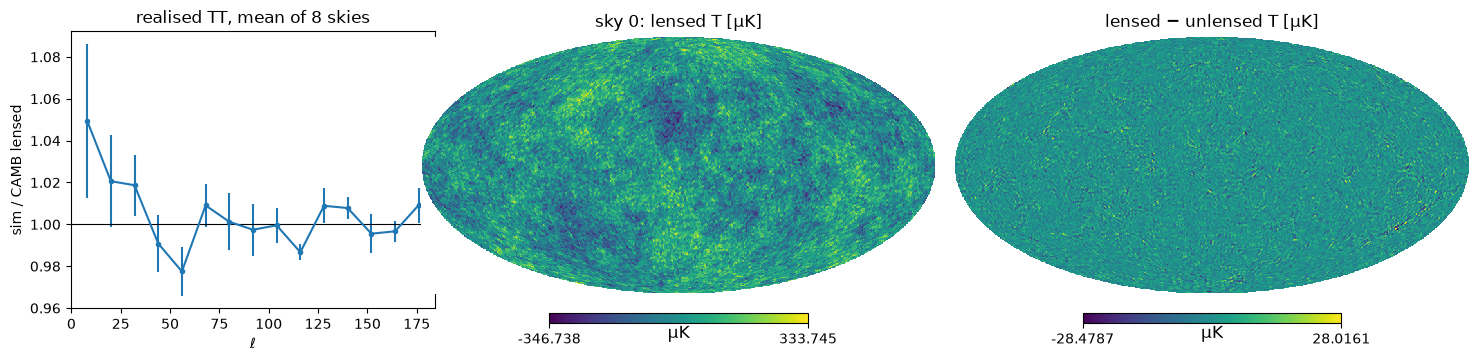

In [5]:
edges = np.arange(2, LMAX + 2, 12)
cen = 0.5 * (edges[1:] + edges[:-1])
ratio = lambda alm: hp.alm2cl(alm)[2:] / spec["len_TT"][2: LMAX + 1]   # ℓ ≥ 2
rat = np.array([[np.mean(ratio(sk["alm"])[a - 2:b - 2]) for a, b in zip(edges[:-1], edges[1:])]
                for sk in skies])

sk = skies[0]
T_len = hp.alm2map(sk["alm"], NSIDE)
T_unl = hp.alm2map(hp.resize_alm(sk["tlm"], CFG.lmax_unl, CFG.lmax_unl, LMAX, LMAX), NSIDE)

fig = plt.figure(figsize=(16, 3.6))
ax = fig.add_subplot(131)
ax.errorbar(cen, rat.mean(0), rat.std(0) / np.sqrt(len(skies)), fmt="o-", ms=3)
ax.axhline(1, color="k", lw=0.8)
ax.set(xlabel=r"$\ell$", ylabel="sim / CAMB lensed", title=f"realised TT, mean of {len(skies)} skies")
hp.mollview(T_len, sub=132, fig=fig, title="sky 0: lensed T [µK]", unit="µK")
hp.mollview(T_len - T_unl, sub=133, fig=fig, title="lensed − unlensed T [µK]", unit="µK")

The scatter at low ℓ is cosmic variance: only 8 skies, each with few modes. At nside 64
lensing is a small effect (a few µK), but it is real map-level remapping, not a
Gaussian field drawn from the lensed spectrum.

## 1d. Anomalies are injected on the primordial T

Anomalies are sky physics, so they act on the **unlensed** T through the
`unlensed_hook` and are then lensed with everything else. Below, sky 0 gets each test
anomaly at a strong amplitude. The maps show *anomalous − twin*, where the twin is the
same sky without the anomaly (the evaluation pairs them the same way).

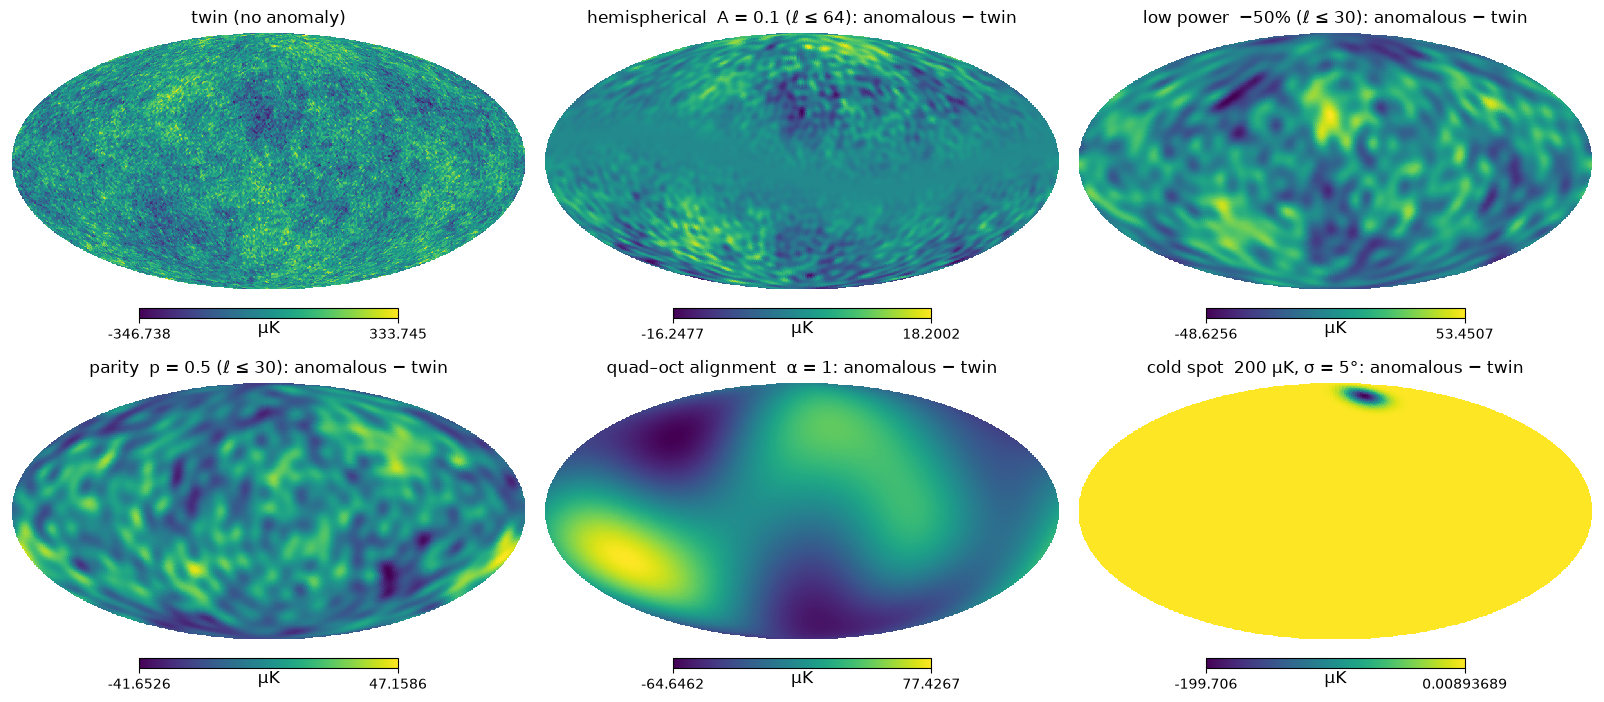

In [6]:
rng = np.random.default_rng(0)
direction = ls.random_direction(rng)
tlm, plm = sk["tlm"], sk["plm"]
hooks = {
    "hemispherical  A = 0.1 (ℓ ≤ 64)": lambda t: ls.inject_hemispherical(t, 0.10, direction),
    "low power  −50% (ℓ ≤ 30)":        lambda t: ls.inject_low_power(t, 0.50),
    "parity  p = 0.5 (ℓ ≤ 30)":        lambda t: ls.inject_parity(t, 0.50),
    "quad–oct alignment  α = 1":       lambda t: ls.inject_planar_alignment(t, 1.0, np.random.default_rng(1)),
    "cold spot  200 µK, σ = 5°":       lambda t: ls.inject_cold_spot(t, 200.0, direction),
}
anom = {name: ls.lens_T(CFG, hook(tlm), plm, NTHREADS) for name, hook in hooks.items()}

fig = plt.figure(figsize=(16, 7))
hp.mollview(T_len, sub=(2, 3, 1), fig=fig, title="twin (no anomaly)", unit="µK")
for k, (name, alm) in enumerate(anom.items()):
    hp.mollview(hp.alm2map(alm - sk["alm"], NSIDE), sub=(2, 3, k + 2), fig=fig,
                title=f"{name}: anomalous − twin", unit="µK")

Ĉ_2, Ĉ_3 twin   : [810.6 681. ]
Ĉ_2, Ĉ_3 aligned: [810.3 679.5]


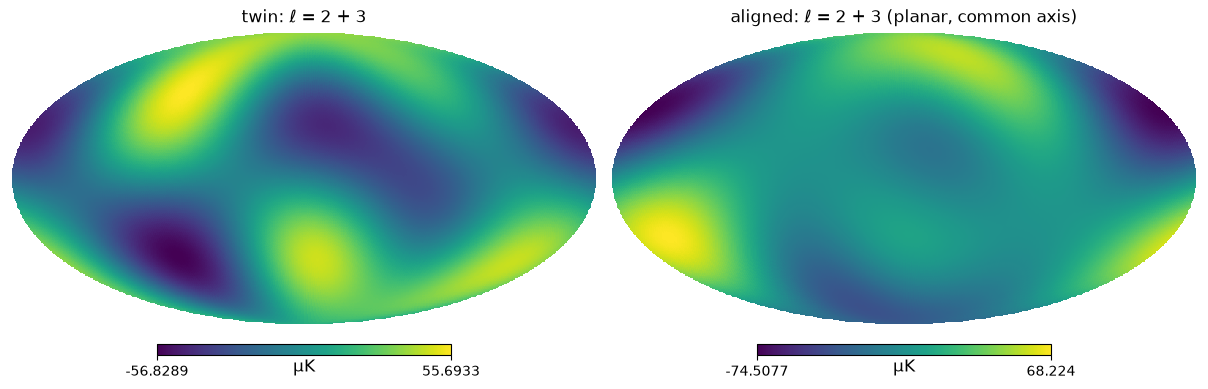

In [7]:
# The alignment anomaly changes only phases, not power: compare the ℓ = 2 + 3 maps.
def low_ell_map(alm, ells=(2, 3)):
    fl = np.isin(np.arange(LMAX + 1), ells).astype(float)
    return hp.alm2map(hp.almxfl(alm, fl), NSIDE)

al = anom["quad–oct alignment  α = 1"]
print("Ĉ_2, Ĉ_3 twin   :", hp.alm2cl(sk["alm"])[2:4].round(1))
print("Ĉ_2, Ĉ_3 aligned:", hp.alm2cl(al)[2:4].round(1))
fig = plt.figure(figsize=(12, 3.6))
hp.mollview(low_ell_map(sk["alm"]), sub=121, fig=fig, title="twin: ℓ = 2 + 3", unit="µK")
hp.mollview(low_ell_map(al), sub=122, fig=fig, title="aligned: ℓ = 2 + 3 (planar, common axis)", unit="µK")

# Training devices

## Fiducial rescaling

Each realisation's $\hat C_\ell$ scatters by cosmic variance, and that is enough to
fingerprint a sky (trial 1 learned mostly this). During training every sky, and its
hard negative, is rescaled ℓ by ℓ to the fiducial lensed $C_\ell$, so the realised
power spectrum can no longer identify it and only phases and morphology can.
Evaluation skies are **not** rescaled; a null test (rescaled vs natural ΛCDM skies,
AUC ≈ 0.5) checks that the network has become blind to realised power.

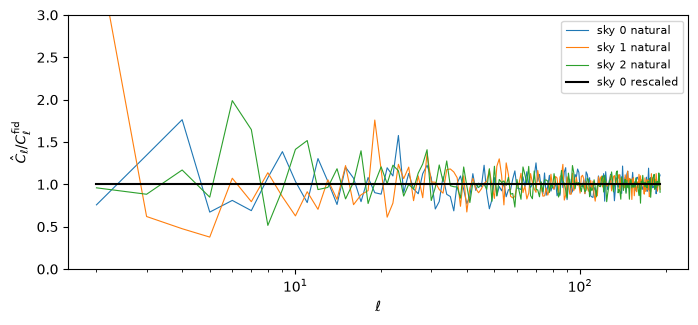

In [8]:
cl_fid = spec["len_TT"]
ell = np.arange(LMAX + 1)
fig, ax = plt.subplots(figsize=(8, 3.3))
for k in range(3):
    ax.plot(ell[2:], ratio(skies[k]["alm"]), lw=0.8, label=f"sky {k} natural")
ax.plot(ell[2:], ratio(ls.rescale_to_cl(skies[0]["alm"], cl_fid)), "k", lw=1.5, label="sky 0 rescaled")
ax.set(xscale="log", xlabel=r"$\ell$", ylabel=r"$\hat C_\ell / C_\ell^{\rm fid}$", ylim=(0, 3))
ax.legend(fontsize=8);

## Hard negatives: the same sky with its primordial T modulated

A hard negative for sky $i$ is
$$T'(\hat n) = T(\hat n)\,[1 + \epsilon\, M(\hat n)]$$
applied to the **unlensed** T, then lensed. $M$ is a Gaussian random field with power
only at $2 \le L \le L_{\rm dev}$ ($L_{\rm dev}$ uniform in 2…10; the dipole is held
out), a random spectrum and unit variance, so it has a random axis and random multipole
content.

Because lensing is linear in T,
$\mathrm{lens}(T(1+\epsilon M)) = \mathrm{lens}(T) + \epsilon\,\mathrm{lens}(T M)$. So
`contrastive_poc/generate_contrastive_poc_skies.py` stores $\delta = \mathrm{lens}(T M)$ (4 per
training sky), and training draws a fresh ε every time.

linearity: max |lens(T(1+εM)) − (lens T + ε lens(TM))| / max = 5.2e-16


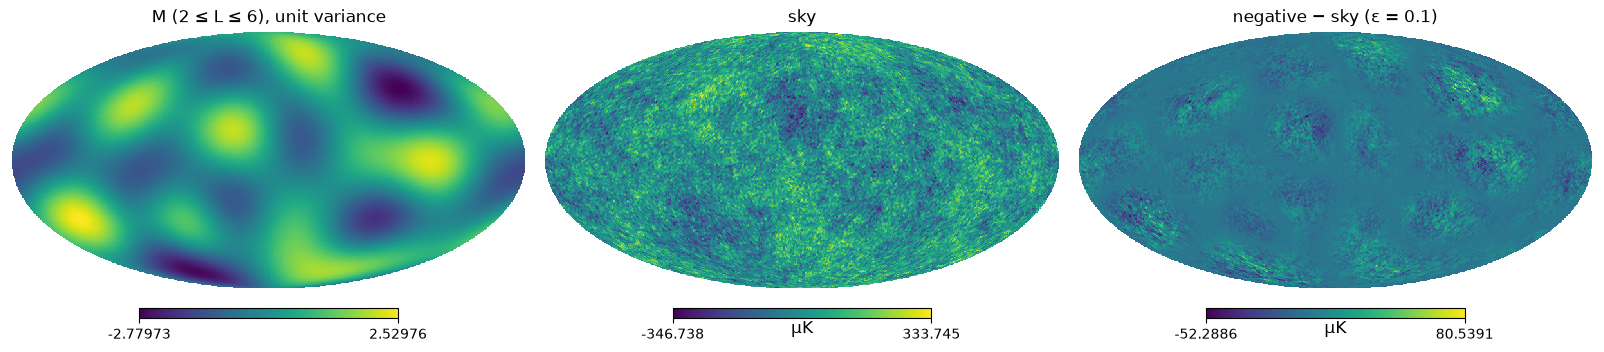

In [9]:
rng = np.random.default_rng(3)
L_dev = 6
M_alm = ls.random_modulation_field(L_dev, rng)
delta = ls.lens_T(CFG, ls.modulation_term(tlm, M_alm), plm, NTHREADS)
eps = 0.10
negative = sk["alm"] + eps * delta

direct = ls.lens_T(CFG, tlm + eps * ls.modulation_term(tlm, M_alm), plm, NTHREADS)
print(f"linearity: max |lens(T(1+εM)) − (lens T + ε lens(TM))| / max = "
      f"{np.abs(direct - negative).max() / np.abs(direct).max():.1e}")

fig = plt.figure(figsize=(16, 3.6))
hp.mollview(hp.alm2map(M_alm, NSIDE), sub=131, fig=fig, title=f"M (2 ≤ L ≤ {L_dev}), unit variance")
hp.mollview(T_len, sub=132, fig=fig, title="sky", unit="µK")
hp.mollview(hp.alm2map(eps * delta, NSIDE), sub=133, fig=fig, title=f"negative − sky (ε = {eps})", unit="µK")

### The ε prior and adaptive ε

`calibrate_modulation_eps.py` sets the prior. For each $L_{\rm dev}$ it finds the ε at
which a *targeted* matched filter that knows M detects the modulation with 50% and 90%
power, at a 5% false-alarm rate, against other ΛCDM skies. Training draws ε
log-uniformly in that range.

That calibration answers an *absolute* question. Training asks a *paired* one (sky vs
its own modulated version), which is much easier, so the negatives saturated within 10
epochs (trial 2). With `--adaptive-eps` the whole prior is multiplied by a factor $s$
each epoch, ×0.7 when hard-negative accuracy is above 95% and ×1.25 when it is below
80%. In trial 3 it settled at $s \approx 0.24$.

{2: (0.089, 0.169), 3: (0.086, 0.17), 4: (0.088, 0.151), 5: (0.088, 0.172), 6: (0.079, 0.149), 7: (0.084, 0.152), 8: (0.071, 0.137), 9: (0.072, 0.136), 10: (0.068, 0.127)}


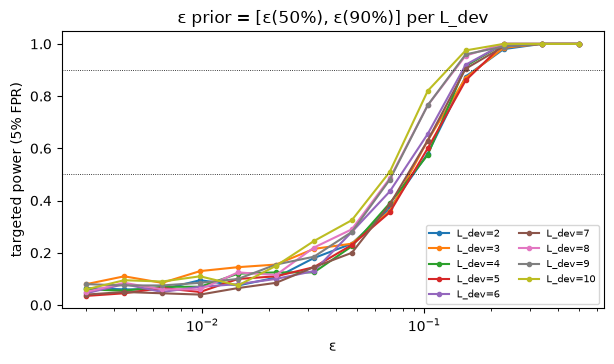

In [10]:
cal_path = POC_DIR / "modulation_eps_calibration.json"
if cal_path.exists():
    cal = json.load(open(cal_path))
    grid = np.array(cal["eps_grid"])
    fig, ax = plt.subplots(figsize=(7, 3.6))
    for Ld, v in cal["table"].items():
        ax.semilogx(grid, v["power"], "o-", ms=3, label=f"L_dev={Ld}")
    for y in (0.5, 0.9):
        ax.axhline(y, color="k", lw=0.6, ls=":")
    ax.set(xlabel="ε", ylabel="targeted power (5% FPR)", title="ε prior = [ε(50%), ε(90%)] per L_dev")
    ax.legend(fontsize=7, ncol=2)
    print({int(Ld): (round(v["eps50"], 3), round(v["eps90"], 3)) for Ld, v in cal["table"].items()})

# Stage 2 — views (per view, on the fly)

## Fixed-frame instrument

* **Mask:** the Planck common intensity mask, downgraded to nside 64, binarised at 0.9
  and apodised with a 2° Gaussian.
* **Noise:** anisotropic white noise from a synthetic scan pattern, with hits
  ∝ 1/cos β in ecliptic latitude β plus deep fields at the ecliptic poles. It is
  normalised to 40 µK·arcmin on average. At nside 64 it is small next to the CMB; the
  real FFP10 noise is the next realism step.
* **Beam:** 160′ FWHM, the usual choice for isotropy tests at nside 64.

Loading mask from /nvme/h/lchristodoulou/cmb/SkySimulation/data/Planck/COM_Mask_CMB-common-Mask-Int_2048_R3.00.fits...


Mask downgraded to nside=64. Sky fraction (f_sky): 75.15%


[Text(0.5, 0, '$\\ell$'),
 Text(0, 0.5, '$b_\\ell$'),
 Text(0.5, 1.0, '160′ beam')]

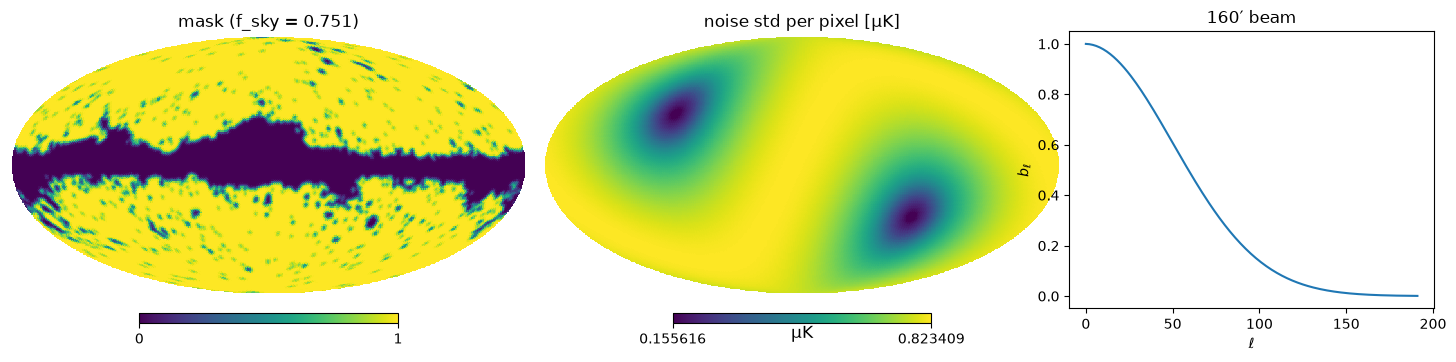

In [11]:
vm = ls.build_view_model(CFG, MASK_PATH)
fig = plt.figure(figsize=(16, 3.6))
hp.mollview(vm.mask, sub=131, fig=fig, title=f"mask (f_sky = {vm.mask.mean():.3f})")
hp.mollview(vm.sigma, sub=132, fig=fig, title="noise std per pixel [µK]", unit="µK")
ax = fig.add_subplot(133)
ax.plot(vm.bl)
ax.set(xlabel=r"$\ell$", ylabel=r"$b_\ell$", title="160′ beam")

## Rotation

The rotation is done exactly in harmonic space with `ducc0.sht.rotate_alm`. It matches
`hp.rotate_alm(matrix=R)` and is about 100× faster. A rotated map satisfies
$m'(\hat n) = m(R^{\mathsf T}\hat n)$.

In [12]:
R = Rotation.random(rng=np.random.default_rng(7))
rot = ls.rotate_alm(sk["alm"], R, LMAX)
ref = sk["alm"].copy(); hp.rotate_alm(ref, matrix=R.as_matrix())
print("ducc vs healpy       :", f"{np.abs(rot - ref).max():.1e}")
print("R then R⁻¹ round trip:", f"{np.abs(ls.rotate_alm(rot, R.inv(), LMAX) - sk['alm']).max():.1e}")
print("C_ℓ preserved        :", np.allclose(hp.alm2cl(rot), hp.alm2cl(sk["alm"])))

ducc vs healpy       : 1.3e-13
R then R⁻¹ round trip: 1.6e-13
C_ℓ preserved        : True


## One training item

This mirrors `ViewDataset.__getitem__` in `cmb-latent/contrastive_common.py`. For sky
$i$:

1. Rescale the sky (and its hard negative) to the fiducial $C_\ell$.
2. **Views A and B:** two independent `make_view_T` calls on the same sky, with
   different rotation and noise and the same mask. This is the **positive pair**.
3. **View N:** the hard negative, sky + ε·δ with ε from the (scaled) prior, viewed the
   same way.
4. Every other view in the batch, such as **view C** of another sky, is also a
   negative.

In the dataset each view is then reordered RING → NEST and fed as two channels:
$T/100\,\mu$K and the mask.

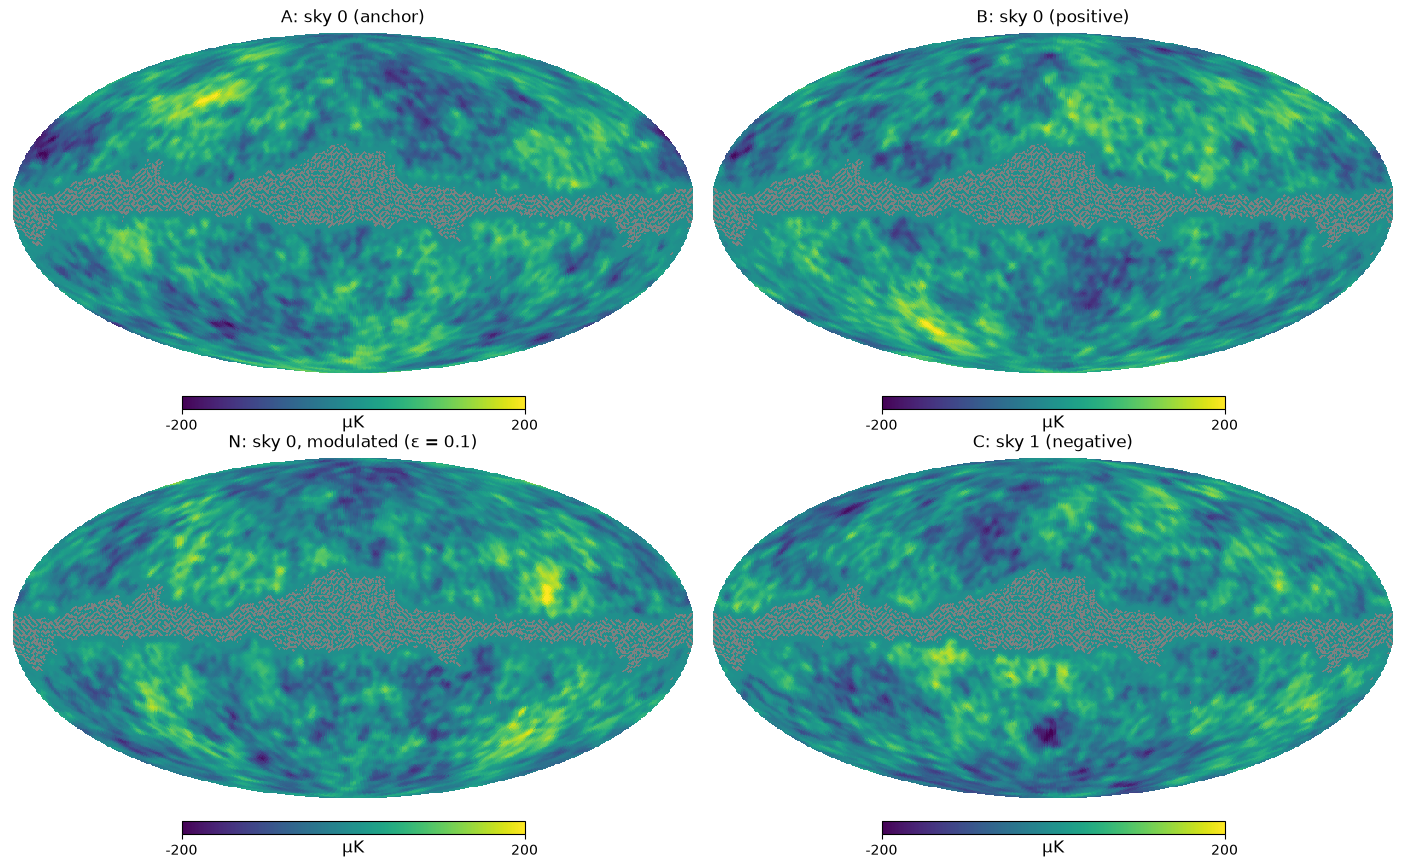

In [13]:
rng = np.random.default_rng(11)
sky_r = ls.rescale_to_cl(sk["alm"], cl_fid)
neg_r = ls.rescale_to_cl(sk["alm"] + eps * delta, cl_fid)
other = ls.rescale_to_cl(skies[1]["alm"], cl_fid)

vA, RA = ls.make_view_T(sky_r, vm, rng)
vB, RB = ls.make_view_T(sky_r, vm, rng)
vN, RN = ls.make_view_T(neg_r, vm, rng)
vC, RC = ls.make_view_T(other, vm, rng)

fig = plt.figure(figsize=(14, 8.5))
for k, (title, v) in enumerate([("A: sky 0 (anchor)", vA), ("B: sky 0 (positive)", vB),
                                (f"N: sky 0, modulated (ε = {eps})", vN), ("C: sky 1 (negative)", vC)]):
    hp.mollview(np.where(vm.mask > 0, v, hp.UNSEEN), sub=(2, 2, k + 1), fig=fig,
                title=title, unit="µK", min=-200, max=200)

### What part of the universe does each view see?

The sky point $\hat n_s$ lands at $R\hat n_s$, so it is visible if `mask(R n_s) > 0`. A
and B see overlapping but different parts of the same universe, so the network has to
recognise the universe from its statistics rather than from particular pixels.

A sees 76.6%, B sees 76.7%, both see 57.1% of the universe


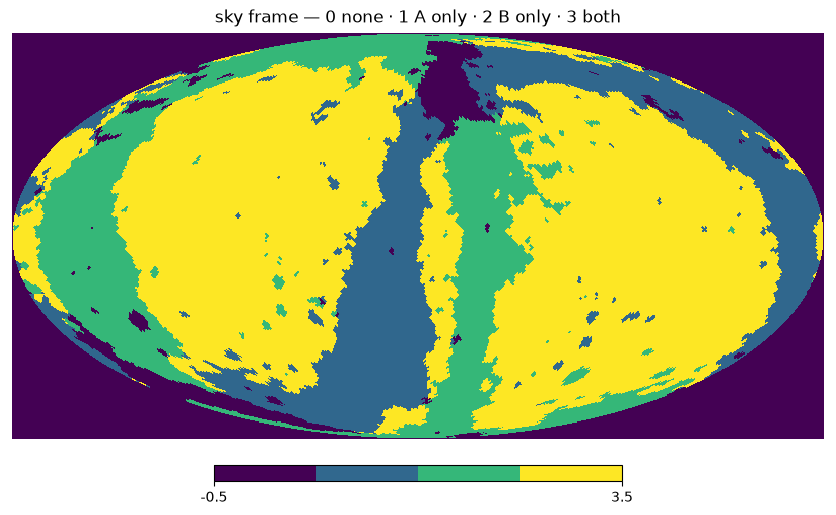

In [14]:
vec = np.array(hp.pix2vec(NSIDE, np.arange(hp.nside2npix(NSIDE))))
seen = lambda R: vm.mask[hp.vec2pix(NSIDE, *(R @ vec))] > 0.5
fA, fB = seen(RA), seen(RB)
print(f"A sees {fA.mean():.1%}, B sees {fB.mean():.1%}, both see {(fA & fB).mean():.1%} of the universe")
hp.mollview(fA.astype(int) + 2 * fB.astype(int), cmap=plt.get_cmap("viridis", 4), min=-0.5, max=3.5,
            title="sky frame — 0 none · 1 A only · 2 B only · 3 both")

In [15]:
n = 200
t0 = time.time()
for _ in range(n):
    ls.make_view_T(sky_r, vm, rng)
print(f"make_view_T: {(time.time() - t0) / n * 1e3:.1f} ms per view")

make_view_T: 8.5 ms per view


# Model and scores (`cmb-latent`)

**Encoder.** The DeepSphere HEALPix encoder (depth 6, nside 64 → 2, 512 channels) is
pooled into the representation *h* = [mean, std over the 48 bottleneck vertices,
**multipole amplitudes** $\sqrt{C_L}$, $1 \le L \le 4$, of each channel]. The multipole
part is a generic, rotation-invariant summary of how features are arranged on the
sphere. A projection head feeds the NT-Xent loss: views A and B are anchors, and every
other view in the batch, including each sky's hard negative, is a negative.

**Scores.** Each sky is scored from 32 views, against held-out ΛCDM reference skies:

* **kNN outlier:** mean cosine distance to the 10 nearest reference skies.
* **PCA-Mahalanobis:** distance from the centre of the reference cloud in its top 32
  principal directions.
* **Cℓ baseline:** Mahalanobis distance of the log pseudo-$C_\ell$ at $2 \le \ell \le 64$
  (no network).
* **global_maxp:** $\max_i[-\log p_i]$ over the three, with each $p_i$ calibrated on the
  reference skies. Its own null distribution (held-out ΛCDM null sims) includes the
  max, so it is the single look-elsewhere-corrected statistic.

## Which anomalies should the embedding capture?

| Anomaly | Type | Tied to a fixed frame? | Expected | Notes |
|---|---|---|---|---|
| Low power ($S_{1/2}$, low quadrupole) | global, low ℓ | no | yes, mostly via the Cℓ baseline | Rescaled training makes the network deliberately power-blind; the Cℓ term in global_maxp covers it. |
| Parity asymmetry | global, ℓ ≲ 30 | no | yes, via the Cℓ baseline | Depends only on the power spectrum. |
| Quadrupole–octopole alignment | global, ℓ = 2, 3 | no (relative) | **yes** | Mutual alignment is rotation-invariant; phase-only, so invisible to $C_\ell$. |
| Hemispherical asymmetry | global | amplitude no, direction yes | **amplitude yes, direction no** | The dipole is held out of the hard negatives, so this tests generalisation from 2 ≤ L ≤ 10 modulation. |
| Alignment with ecliptic or dipole, north–south *ecliptic* asymmetry | global | **yes** | **no** | Random rotations remove fixed reference directions. |
| Cold spot | localised, ~5–10° | location yes | partial | Hidden by the mask in ~40% of pairs; a tail event rather than something unseen. |
| Lensing amplitude ($A_L$) | global, ℓ ≳ 1000 | no | weak | Little signal below $\ell_{\max}=191$. |

## Results so far (AUC vs the ΛCDM null, strongest amplitude)

| | Trial 1: plain | Trial 2: + rescaling + hard negatives | Trial 4: trial 2 + multipole pooling | **Trial 3: + pooling + adaptive ε** |
|---|---|---|---|---|
| Hemispherical, A = 0.10 (kNN) | 0.53 | 0.58 | 0.65 | **0.84** (46% detected at 5% false-alarm rate) |
| Alignment, α = 1 (kNN) | 0.66 | 0.64 | **0.74** | 0.71 |
| Cold spot, 200 µK (kNN) | 0.62 | 0.61 | 0.61 | 0.58 |
| Low power / parity (Cℓ baseline) | 1.00 | 1.00 | 1.00 | 1.00 |
| global_maxp: hemispherical A = 0.10 / alignment α = 1 | 0.52 / 0.62 | 0.54 / 0.62 | 0.58 / 0.67 | **0.76 / 0.66** |
| Null test (kNN; 0.5 = blind to realised power) | 0.26 | 0.41 | 0.45 | **0.46** |

Trial 4 is the ablation. The **multipole pooling** mainly helps alignment (it encodes
the large-scale arrangement of features). The **adaptive ε** drives the hemispherical
gain: keeping the modulation negatives hard all through training makes the network
sensitive to modulation, and that carries over to the held-out dipole. Neither helps
the localised cold spot. Results are in `cmb-latent/runs/contrastive_poc_nside64_trial_*/eval/`.

## Next steps

* Replace the synthetic noise with FFP10 SMICA noise sims and add foreground-residual
  templates, so the null sims match the real data. This is the main remaining threat to
  a valid real-sky p-value.
* Settle the global combination rule (max vs Fisher's sum) on sims, then freeze the
  pipeline (pre-registration) before scoring the real SMICA map.
* Quote final sensitivities on freshly seeded anomaly sims.